In [1]:
import sys
import json

import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

sys.path.append("../../PG_PyTraining")
from common.pg.pg_geometry import PgCamera

In [2]:
with open("../../PG_PyTraining/common/pg/resources/cam_params.json", "rt") as f:
    params = json.load(f)

cam2 = params["Cam2"]["LENS_PARAMS"]

K = np.array([
    [cam2["FX"], 0, cam2["CX"]],
    [0, cam2["FY"], cam2["CY"]],
    [0, 0, 1],
])
D = np.array([cam2["K0"], cam2["K1"], cam2["K2"], cam2["K3"]])[:, None]

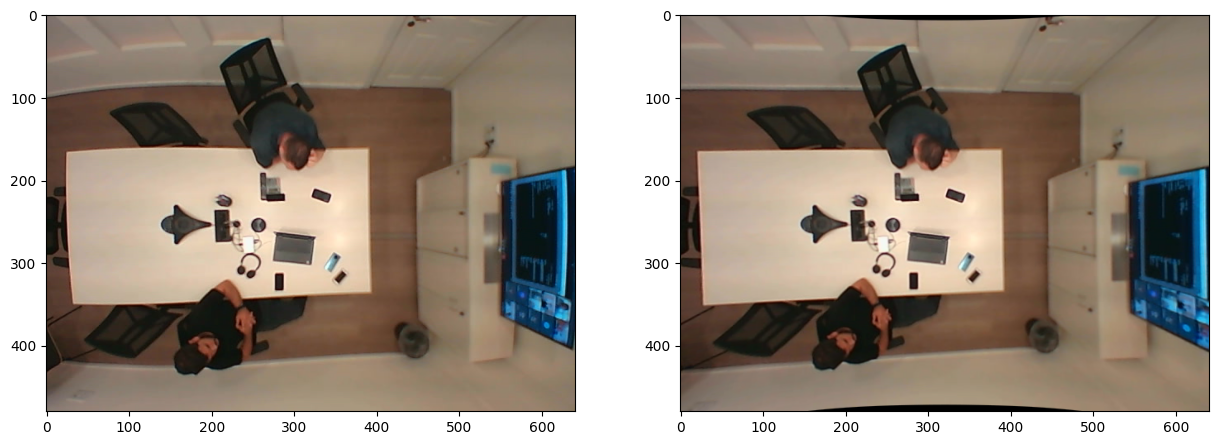

In [3]:
img = cv2.cvtColor(cv2.imread("data/Cam2_H256_atiryeda_mr_0101_2.png"), cv2.COLOR_BGR2RGB)
undist_img = cv2.fisheye.undistortImage(img, K, D, Knew=K)

plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.subplot(1, 2, 2)
plt.imshow(undist_img)

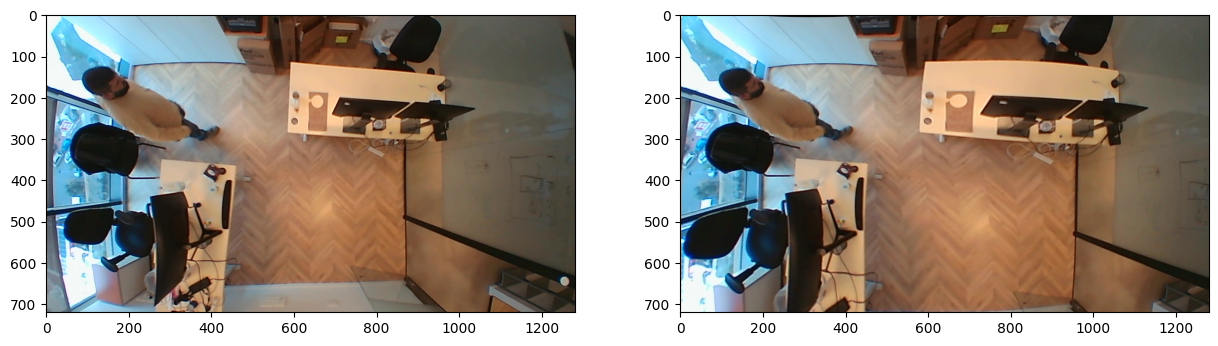

In [4]:
img = cv2.cvtColor(cv2.imread("data/Cam2_H256_Menivim_cs_3.png"), cv2.COLOR_BGR2RGB)
undist_img = cv2.fisheye.undistortImage(img, K, D, Knew=K)

plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.subplot(1, 2, 2)
plt.imshow(undist_img)

In [5]:
with open("data/Cam2_H256_Menivim_cs_3.json", "rt") as f:
    data = json.load(f)

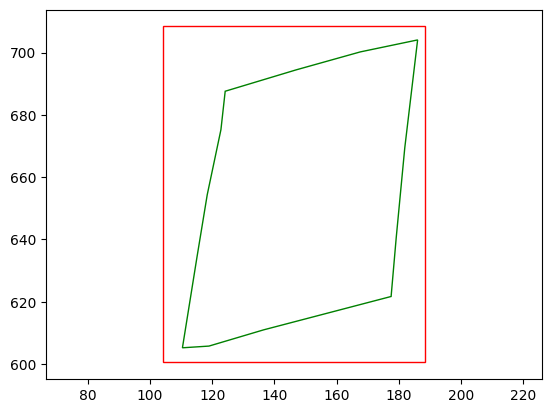

In [9]:
shapes = []
for shape in data["shapes"]:
    if shape["label"] not in ["cabinet", "cabinet_mask"]:
        continue
    if shape["shape_type"] == "rectangle":
        shapes.append(Rectangle(
            shape["points"][0],
            shape["points"][1][0] - shape["points"][0][0],
            shape["points"][1][1] - shape["points"][0][1],
            fill=False, color="r"))
    else:
        shapes.append(Polygon(shape["points"], fill=False, color="g"))

fig, ax = plt.subplots() 
for shape in shapes:
    ax.add_patch(shape)


plt.xlim(0, 640)
plt.ylim(0, 480)
plt.axis("equal")
plt.show()

In [10]:
camera = PgCamera(2560, "Cam2")

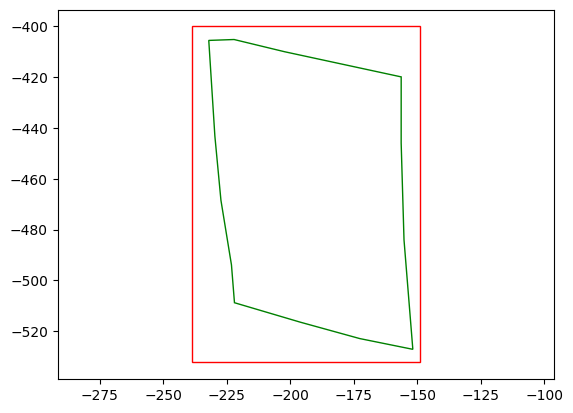

In [12]:
shapes = []
for shape in data["shapes"]:
    if shape["label"] not in ["cabinet", "cabinet_mask"]:
        continue
    points = camera.pixel2cm(shape["points"])
    if shape["shape_type"] == "rectangle":
        shapes.append(Rectangle(
            points[0],
            points[1][0] - points[0][0],
            points[1][1] - points[0][1],
            fill=False, color="r"))
    else:
        shapes.append(Polygon(points, fill=False, color="g"))

fig, ax = plt.subplots() 
for shape in shapes:
    ax.add_patch(shape)


plt.xlim(-500, 500)
plt.ylim(-200, 200)
# plt.xlim(0, 640)
# plt.ylim(0, 480)
plt.axis("equal")
plt.show()

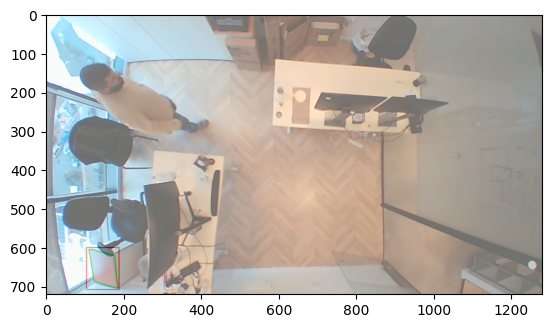

In [14]:
mask = np.zeros((720, 1280, 3), dtype=np.uint8) + 255
shapes = []
for shape in data["shapes"]:
    if shape["label"] not in ["cabinet", "cabinet_mask"]:
        continue
    points = np.array(shape["points"], dtype=int)
    if shape["shape_type"] == "rectangle":
        cv2.rectangle(mask, points[0], points[1], (255, 0, 0), 2)
    else:
        cv2.polylines(mask, points[None], True, (0, 255, 0), 2)
        
alpha = 0.4  # Transparency factor.
# Following line overlays transparent rectangle over the image
output_image = cv2.addWeighted(mask, alpha, img, 1 - alpha, 0)
plt.imshow(output_image)


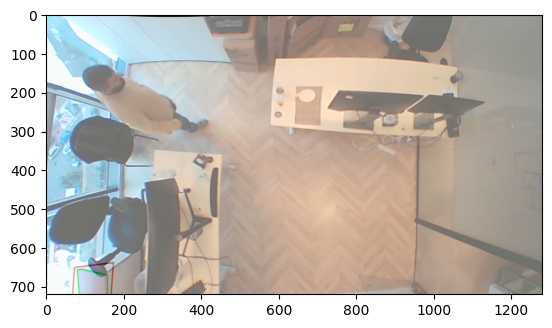

In [15]:
undist_mask = cv2.fisheye.undistortImage(mask, K, D, Knew=K)
alpha = 0.4  # Transparency factor.
# Following line overlays transparent rectangle over the image
output_image = cv2.addWeighted(undist_mask, alpha, undist_img, 1 - alpha, 0)
plt.imshow(output_image)

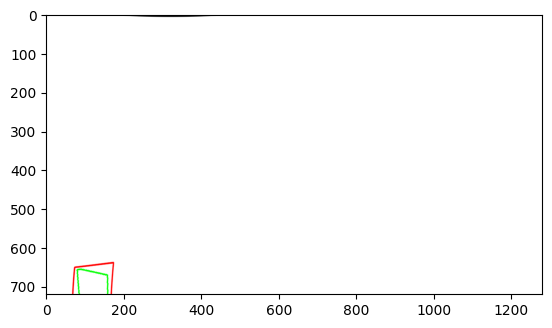

In [16]:
plt.imshow(undist_mask)

In [17]:
def rectangle_to_polygon(rectangle, n):
    # Extract coordinates of top-left and bottom-right corners
    top_left = rectangle[0]
    bottom_right = rectangle[1]

    # Calculate coordinates of other corners
    top_right = np.array([top_left[0], bottom_right[1]])
    bottom_left = np.array([bottom_right[0], top_left[1]])

    # Generate points along each side
    top_side = np.linspace(top_left, top_right, n, endpoint=False)
    right_side = np.linspace(top_right, bottom_right, n, endpoint=False)
    bottom_side = np.linspace(bottom_right, bottom_left, n, endpoint=False)
    left_side = np.linspace(bottom_left, top_left, n, endpoint=False)

    # Combine points to form the polygon
    polygon = np.concatenate([top_side, right_side, bottom_side, left_side])

    return polygon

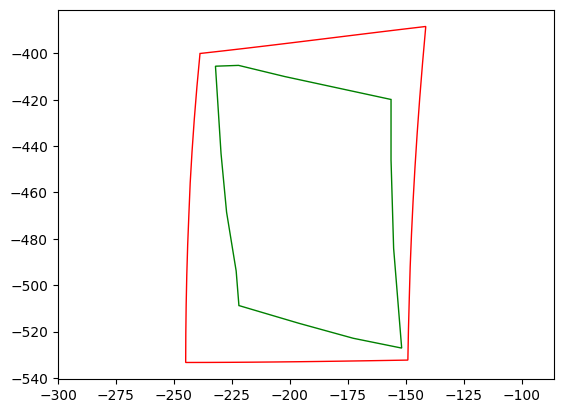

In [19]:
shapes = []
for shape in data["shapes"]:
    if shape["label"] not in ["cabinet", "cabinet_mask"]:
        continue
    if shape["shape_type"] == "rectangle":
        points = camera.pixel2cm(rectangle_to_polygon(shape["points"], 10))
        shapes.append(Polygon(points, fill=False, color="r"))
    else:
        points = camera.pixel2cm(shape["points"])
        shapes.append(Polygon(points, fill=False, color="g"))

fig, ax = plt.subplots() 
for shape in shapes:
    ax.add_patch(shape)


plt.xlim(-500, 500)
plt.ylim(-200, 200)
# plt.xlim(0, 640)
# plt.ylim(0, 480)
plt.axis("equal")
plt.show()

In [20]:
cam3 = params["Cam3"]["LENS_PARAMS"]

K = np.array([
    [cam3["FX"], 0, cam3["CX"]],
    [0, cam3["FY"], cam3["CY"]],
    [0, 0, 1],
])
D = np.array([cam3["K0"], cam3["K1"], cam3["K2"], cam3["K3"]])[:, None]

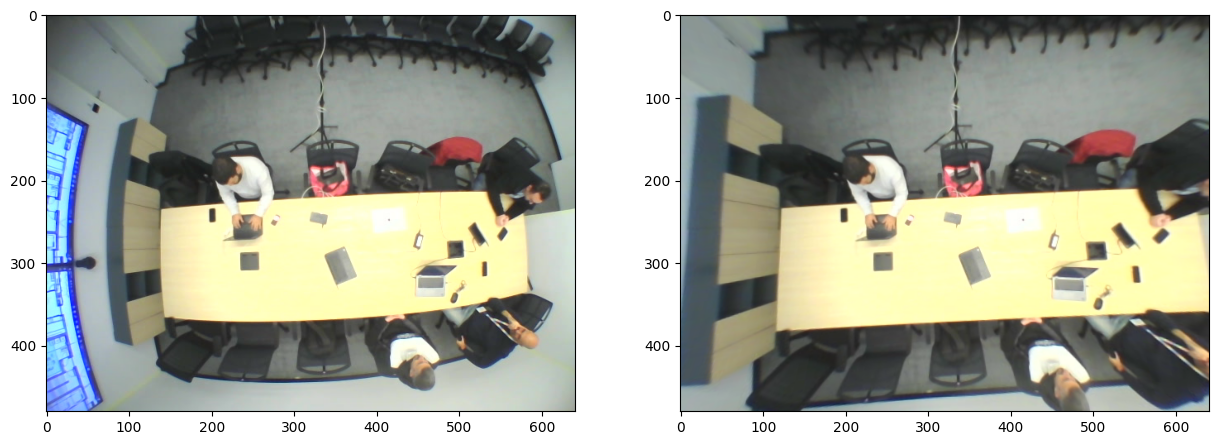

In [21]:
img = cv2.cvtColor(cv2.imread("data/Cam3_H242_discount_1.png"), cv2.COLOR_BGR2RGB)
undist_img = cv2.fisheye.undistortImage(img, K, D, Knew=K)

plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.subplot(1, 2, 2)
plt.imshow(undist_img)

In [22]:
with open("data/Cam3_H242_discount_1.json", "rt") as f:
    data = json.load(f)

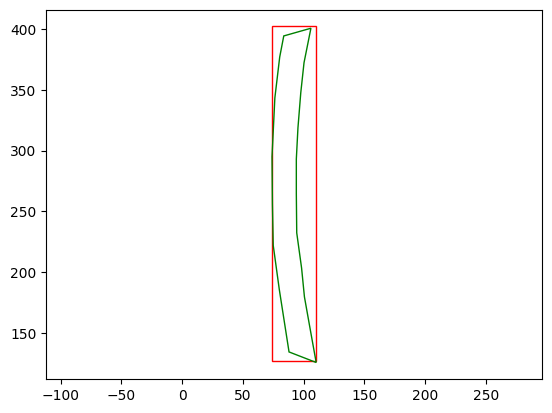

In [23]:
shapes = []
for shape in data["shapes"]:
    if shape["shape_type"] == "rectangle":
        shapes.append(Rectangle(
            shape["points"][0],
            shape["points"][1][0] - shape["points"][0][0],
            shape["points"][1][1] - shape["points"][0][1],
            fill=False, color="r"))
    else:
        shapes.append(Polygon(shape["points"], fill=False, color="g"))

fig, ax = plt.subplots() 
for shape in shapes:
    ax.add_patch(shape)


plt.xlim(0, 640)
plt.ylim(0, 480)
plt.axis("equal")
plt.show()

In [24]:
camera = PgCamera(2420, "Cam3")

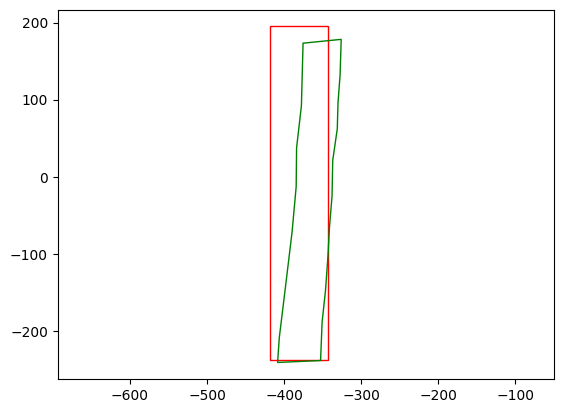

In [25]:
shapes = []
for shape in data["shapes"]:
    points = camera.pixel2cm(shape["points"])
    if shape["shape_type"] == "rectangle":
        shapes.append(Rectangle(
            points[0],
            points[1][0] - points[0][0],
            points[1][1] - points[0][1],
            fill=False, color="r"))
    else:
        shapes.append(Polygon(points, fill=False, color="g"))

fig, ax = plt.subplots() 
for shape in shapes:
    ax.add_patch(shape)


plt.xlim(-500, 500)
plt.ylim(-200, 200)
# plt.xlim(0, 640)
# plt.ylim(0, 480)
plt.axis("equal")
plt.show()

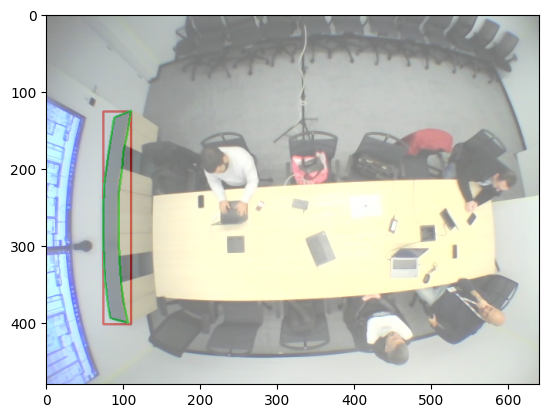

In [26]:
mask = np.zeros((480, 640, 3), dtype=np.uint8) + 255
shapes = []
for shape in data["shapes"]:
    points = np.array(shape["points"], dtype=int)
    if shape["shape_type"] == "rectangle":
        cv2.rectangle(mask, points[0], points[1], (255, 0, 0), 2)
    else:
        cv2.polylines(mask, points[None], True, (0, 255, 0), 2)
        
alpha = 0.4  # Transparency factor.
# Following line overlays transparent rectangle over the image
output_image = cv2.addWeighted(mask, alpha, img, 1 - alpha, 0)
plt.imshow(output_image)


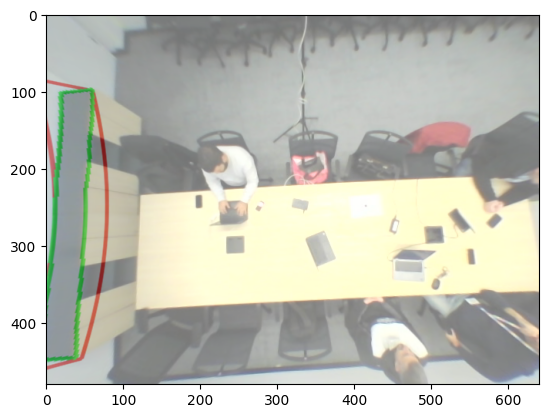

In [27]:
undist_mask = cv2.fisheye.undistortImage(mask, K, D, Knew=K)
alpha = 0.4  # Transparency factor.
# Following line overlays transparent rectangle over the image
output_image = cv2.addWeighted(undist_mask, alpha, undist_img, 1 - alpha, 0)
plt.imshow(output_image)

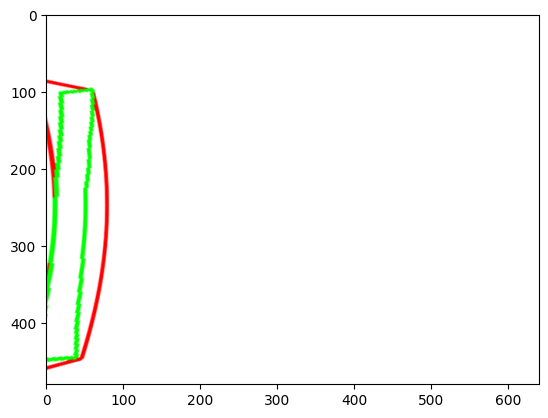

In [28]:
plt.imshow(undist_mask)

In [29]:
def rectangle_to_polygon(rectangle, n):
    # Extract coordinates of top-left and bottom-right corners
    top_left = rectangle[0]
    bottom_right = rectangle[1]

    # Calculate coordinates of other corners
    top_right = np.array([top_left[0], bottom_right[1]])
    bottom_left = np.array([bottom_right[0], top_left[1]])

    # Generate points along each side
    top_side = np.linspace(top_left, top_right, n, endpoint=False)
    right_side = np.linspace(top_right, bottom_right, n, endpoint=False)
    bottom_side = np.linspace(bottom_right, bottom_left, n, endpoint=False)
    left_side = np.linspace(bottom_left, top_left, n, endpoint=False)

    # Combine points to form the polygon
    polygon = np.concatenate([top_side, right_side, bottom_side, left_side])

    return polygon

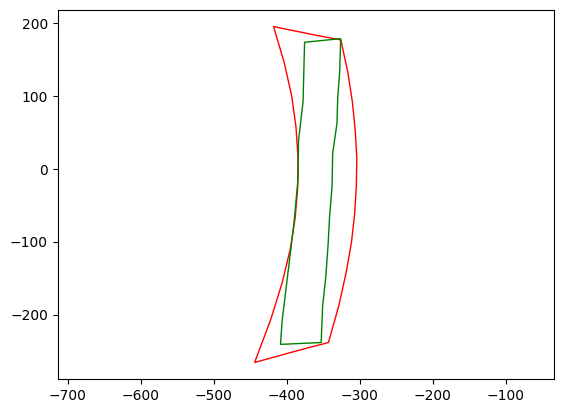

In [30]:
shapes = []
for shape in data["shapes"]:
    
    if shape["shape_type"] == "rectangle":
        points = camera.pixel2cm(rectangle_to_polygon(shape["points"], 10))
        shapes.append(Polygon(points, fill=False, color="r"))
    else:
        points = camera.pixel2cm(shape["points"])
        shapes.append(Polygon(points, fill=False, color="g"))

fig, ax = plt.subplots() 
for shape in shapes:
    ax.add_patch(shape)


plt.xlim(-500, 500)
plt.ylim(-200, 200)
# plt.xlim(0, 640)
# plt.ylim(0, 480)
plt.axis("equal")
plt.show()